In [1]:
import pandas as pd

In [48]:
df = pd.read_csv('/Users/dmatekenya/Library/CloudStorage/GoogleDrive-dmatekenya@gmail.com/My Drive/TEACHING/AIMS-DSCBI/data/other/grades-dec.csv')

In [49]:
df = df.query("drop == 'No'").copy()

<Axes: xlabel='perfomance_cat'>

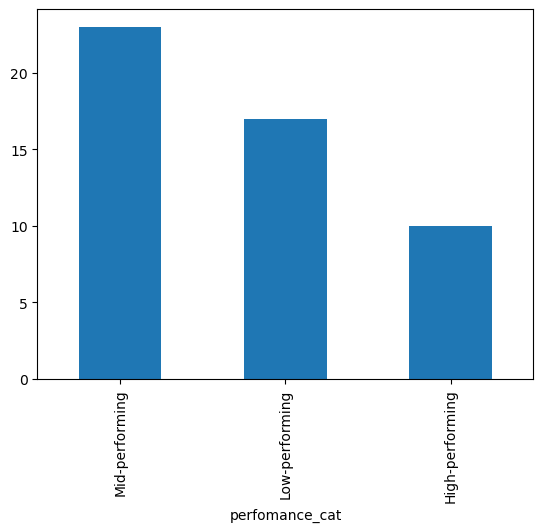

In [6]:
df['perfomance_cat'].value_counts().plot(kind='bar')

In [52]:
df.columns

Index(['avg_quiz', 'avg_assig\n', 'project', 'weighted_average',
       'perfomance_cat', 'drop'],
      dtype='object')

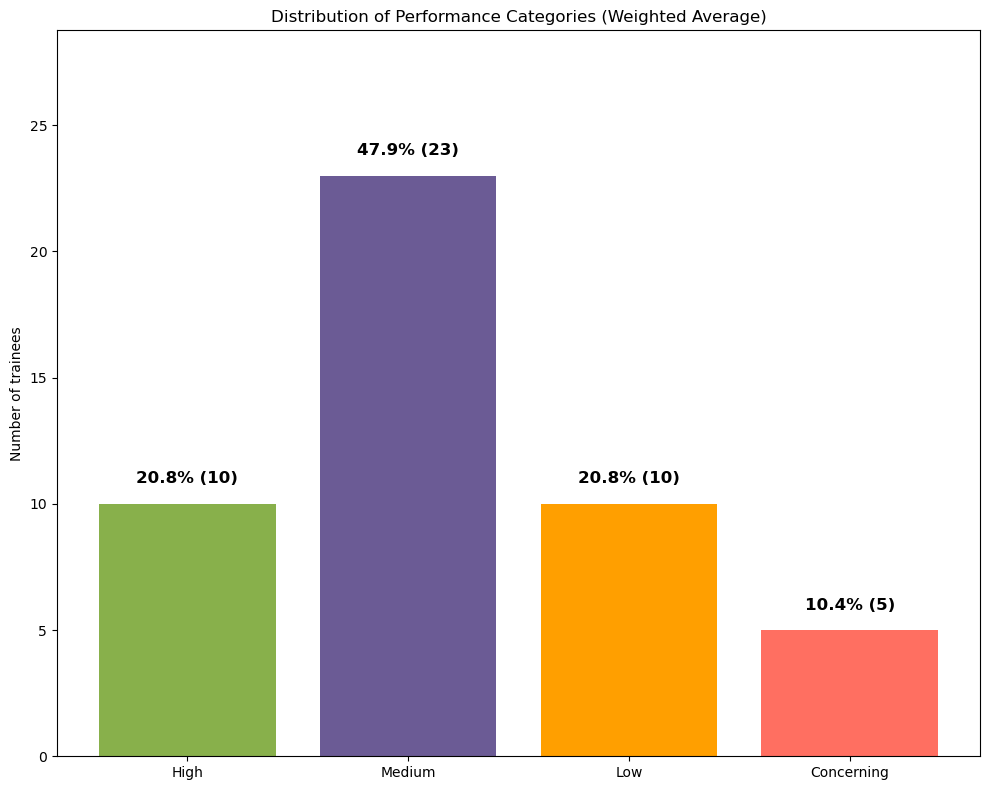

In [53]:
import matplotlib.pyplot as plt

# Create new category based on weighted_average
def categorize_score(score):
    if score >= 80:
        return 'High'
    elif score >= 60:
        return 'Medium'
    elif score >= 50:
        return 'Low'
    else:
        return 'Concerning'

df['score_category'] = df['weighted_average'].apply(categorize_score)

# Calculate counts & percentages
counts = df['score_category'].value_counts()
total = counts.sum()
percentages = (counts / total) * 100

# Define order and colors for categories
category_order = ['High', 'Medium', 'Low', 'Concerning']
colors = ["#88B04B", "#6B5B95", "#FF9F00", "#FF6F61"]

# Reindex to ensure proper order
counts = counts.reindex(category_order, fill_value=0)
percentages = percentages.reindex(category_order, fill_value=0)

plt.figure(figsize=(10,8))
bars = plt.bar(counts.index, counts.values, color=colors)

plt.ylabel("Number of trainees")
plt.title("Distribution of Performance Categories (Weighted Average)")
plt.xticks(rotation=0)

# Increase y-axis limit so labels have safe space above bars
max_height = max(counts.values)
plt.ylim(0, max_height * 1.25)

# Add percentage labels with counts in brackets
for bar, pct, count in zip(bars, percentages, counts.values):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + max_height * 0.03,
        f"{pct:.1f}% ({int(count)})",
        ha='center',
        va='bottom',
        fontsize=12,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


In [45]:
df

,avg_quiz,avg_assig\n,project,weighted_average,perfomance_cat
0,56.01,26.50,62.35,55.09,Low-performing
1,58.05,62.93,65.88,63.53,Mid-performing
2,42.81,52.22,NaN,18.63,Low-performing
3,76.94,96.36,86.27,85.65,High-performing
4,60.82,80.68,73.33,71.50,Mid-performing
5,72.82,45.00,NaN,24.68,Low-performing
6,63.71,30.00,50.59,50.44,Low-performing
7,65.02,83.04,69.41,70.54,Mid-performing
8,63.09,46.50,58.82,57.87,Low-performing
9,52.64,35.00,70.59,60.59,Mid-performing


In [20]:
df.columns

Index(['avg_quiz', 'avg_assig\n', 'project', 'weighted_average',
       'perfomance_cat'],
      dtype='object')

In [55]:
df.shape

(48, 7)

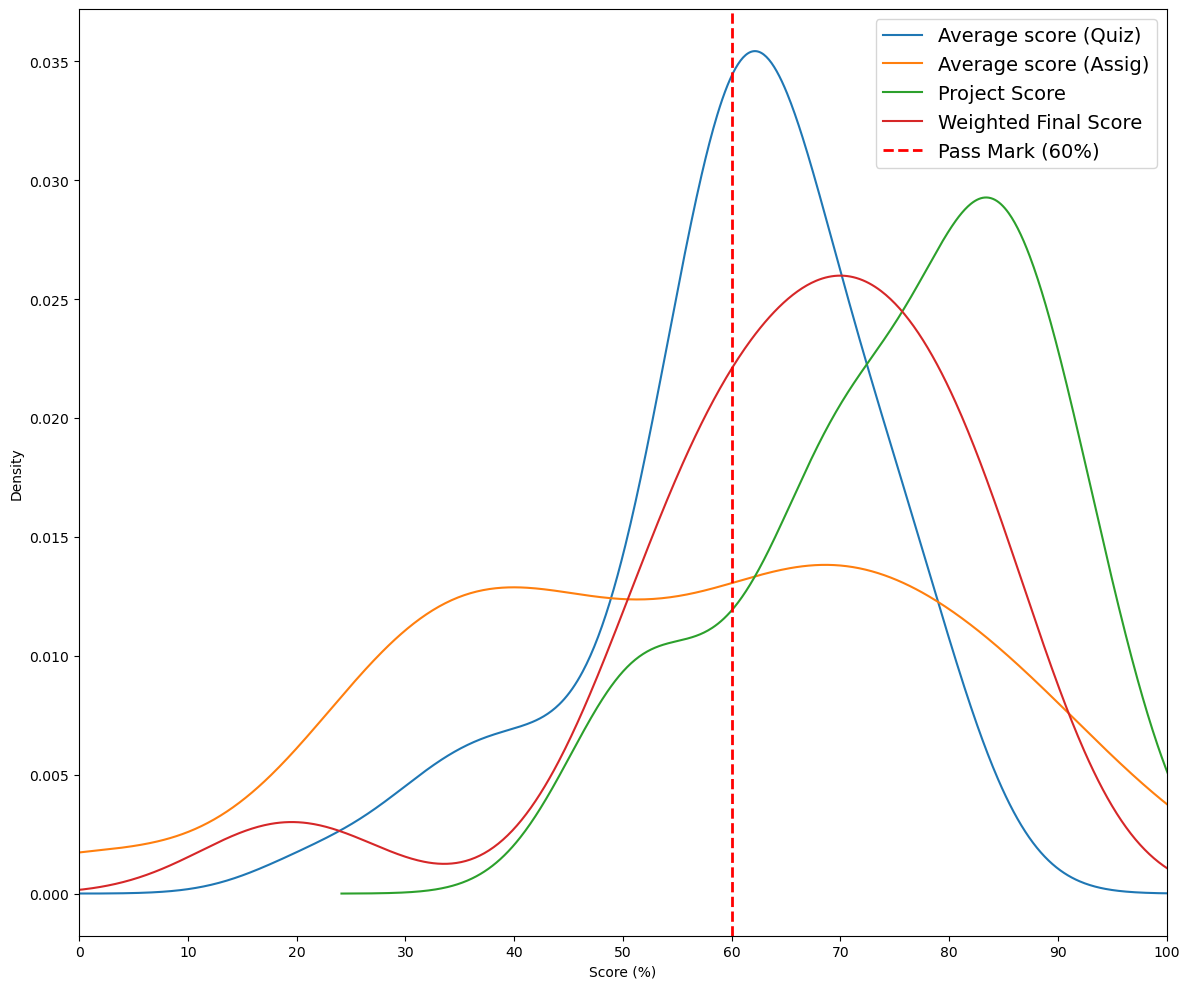

In [54]:
# Extract relevant columns
quiz = df['avg_quiz'].dropna()
assign = df['avg_assig\n'].dropna()
project = df['project'].dropna()
weighted_final = df['weighted_average'].dropna()

plt.figure(figsize=(12,10))

# KDE line plots with updated legend labels
quiz.plot(kind='kde', label='Average score (Quiz)')
assign.plot(kind='kde', label='Average score (Assig)')
project.plot(kind='kde', label='Project Score')
weighted_final.plot(kind='kde', label='Weighted Final Score')


# X-axis as percentages 0–100
plt.xlim(0, 100)
plt.xticks(range(0, 101, 10))

# Vertical line at 60% pass mark
plt.axvline(60, color='red', linestyle='--', linewidth=2, label='Pass Mark (60%)')

plt.xlabel("Score (%)")
plt.ylabel("Density")

plt.legend(fontsize=14)
plt.tight_layout()
plt.show()

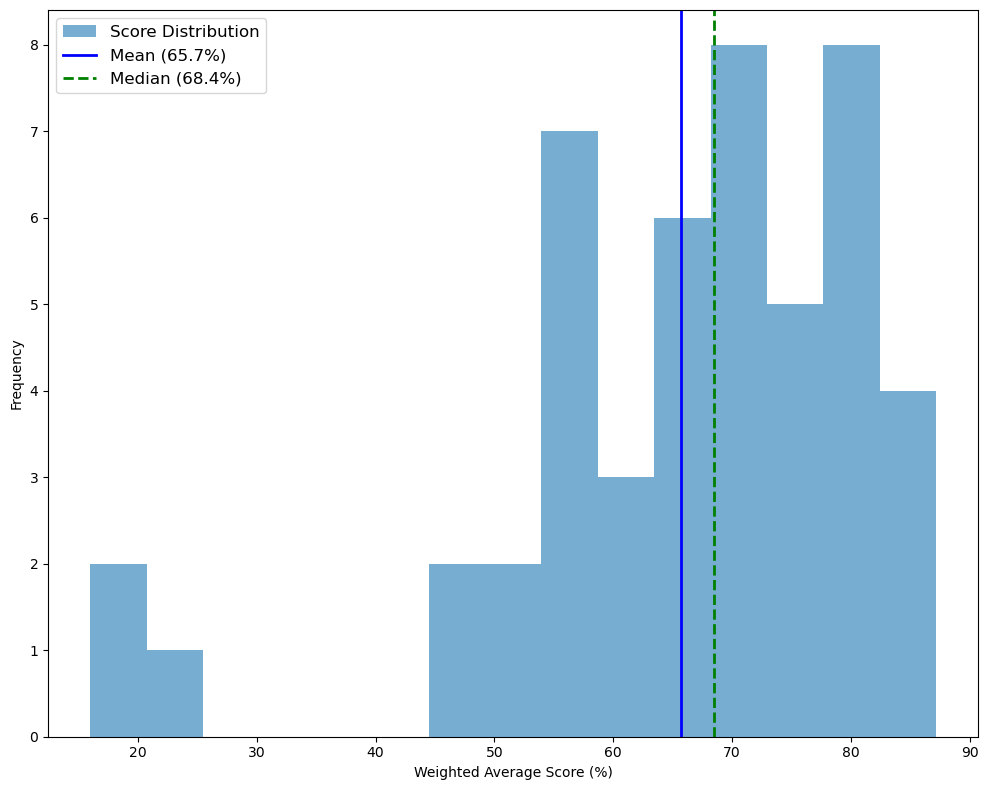

In [56]:
# Extract weighted averages
scores = df['weighted_average'].dropna()

# Compute statistics
mean_score = scores.mean()
median_score = scores.median()

plt.figure(figsize=(10,8))

# Histogram
plt.hist(scores, bins=15, alpha=0.6, label="Score Distribution")

# Vertical lines with legend labels
plt.axvline(mean_score, color='blue', linestyle='-', linewidth=2, label=f"Mean ({mean_score:.1f}%)")
plt.axvline(median_score, color='green', linestyle='--', linewidth=2, label=f"Median ({median_score:.1f}%)")

# Labels
plt.xlabel("Weighted Average Score (%)")
plt.ylabel("Frequency")

plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

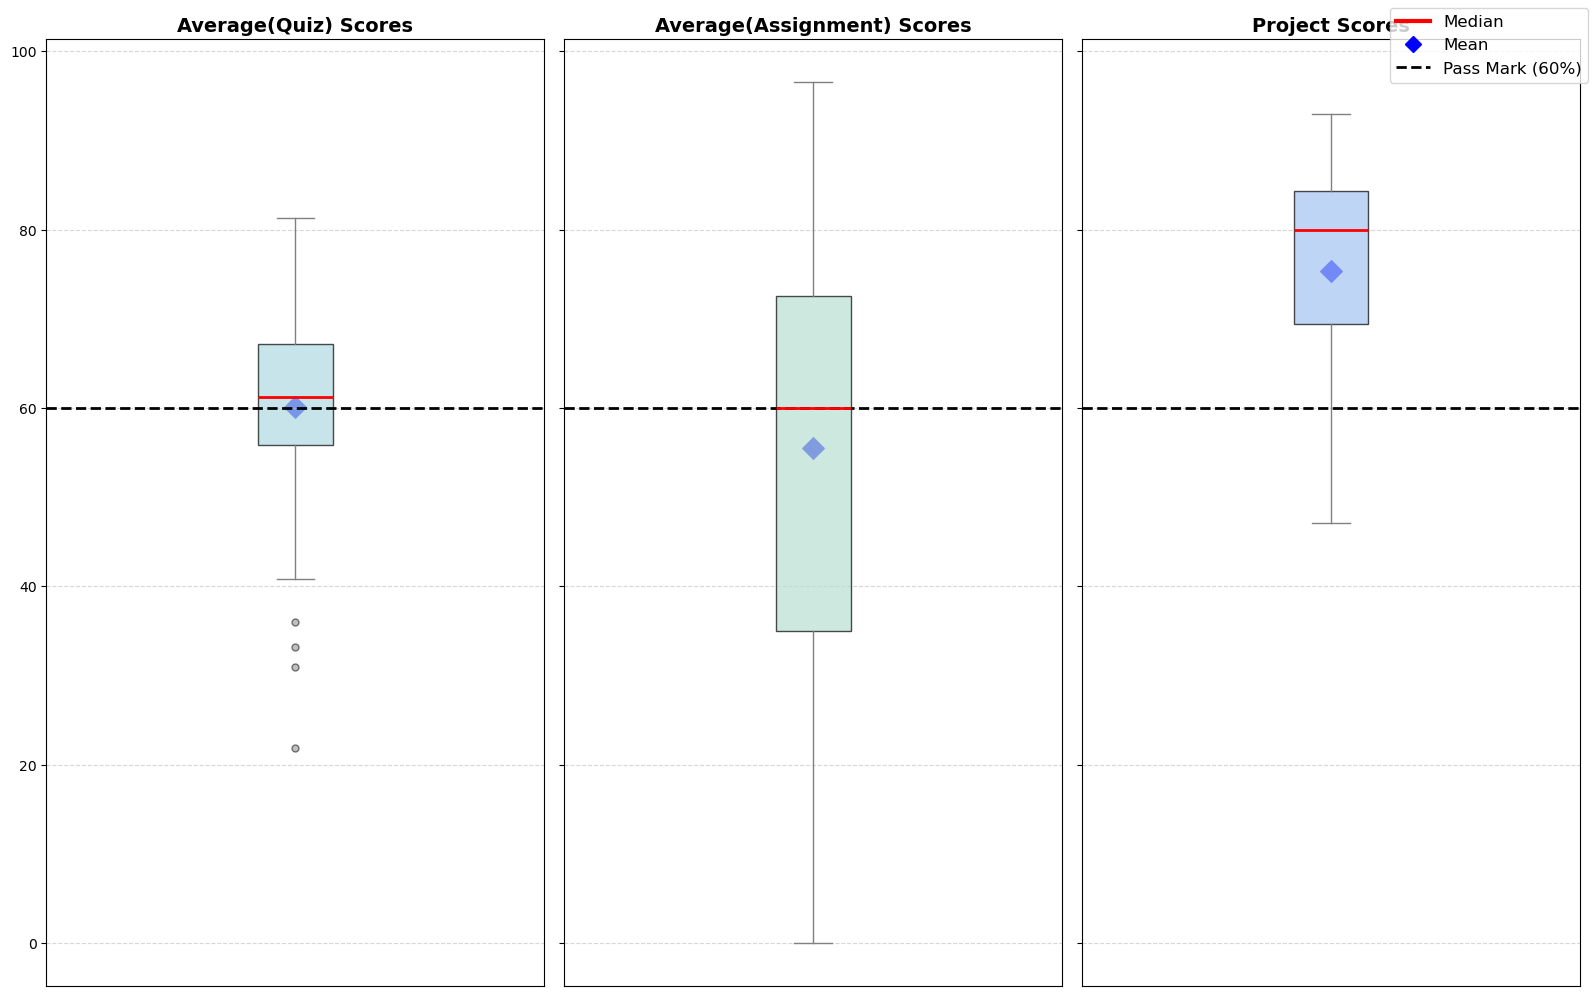

In [57]:
import pandas as pd
import matplotlib.pyplot as plt



quiz = df["avg_quiz"].dropna()
assign = df['avg_assig\n'].dropna()
project = df["project"].dropna()

datasets = [quiz, assign, project]
labels = ["Average(Quiz)", "Average(Assignment)", "Project"]

means = [d.mean() for d in datasets]
medians = [d.median() for d in datasets]

fig, axes = plt.subplots(1, 3, figsize=(16, 10), sharey=True)

colors = ["#AED9E0", "#B8E0D2", "#A3C4F3"]

for ax, data, label, mean_val, median_val, color in zip(axes, datasets, labels, means, medians, colors):
    
    # Boxplot
    ax.boxplot(
        data,
        vert=True,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.7),
        medianprops=dict(color="red", linewidth=2),
        whiskerprops=dict(color="gray"),
        capprops=dict(color="gray"),
        flierprops=dict(marker='o', markersize=5, markerfacecolor='gray', alpha=0.5),
    )
    
    # Mean marker (blue diamond)
    ax.scatter(1, mean_val, color="blue", s=120, marker="D")

    # Horizontal pass mark
    ax.axhline(60, color="black", linestyle="--", linewidth=2)

    ax.set_title(f"{label} Scores", fontsize=14, fontweight="bold")
    ax.set_xticks([])
    ax.grid(axis='y', linestyle='--', alpha=0.5)

# Legend
handles = [
    plt.Line2D([0], [0], color='red', linewidth=3, label='Median'),
    plt.Line2D([0], [0], marker='D', color='blue', markersize=8, linestyle='None', label='Mean'),
    plt.Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='Pass Mark (60%)')
]

fig.legend(handles=handles, loc="upper right", fontsize=12)

plt.tight_layout()
plt.show()

In [36]:
df.describe()

,avg_quiz,avg_assig\n,project,weighted_average
count,50.000000,50.000000,47.000000,50.000000
mean,58.199600,53.254400,75.560851,65.105200
std,15.719775,25.650959,13.001205,15.902972
min,11.570000,0.000000,47.060000,15.990000
25%,53.312500,35.000000,69.410000,56.935000
50%,61.055000,54.720000,80.000000,68.300000
75%,67.060000,71.732500,84.320000,76.372500
max,81.310000,96.500000,92.940000,87.180000
